# 01 – Données obligataires (Groupe 2, Phase 2)

**Source** : 5 obligations simulées (exemple du guide, section Projet 2), nominal 100, coupons annuels, maturités 1 à 5 ans. Les niveaux de prix sont cohérents avec une courbe de taux croissante de l'ordre de 2,5 % à 4 %.

**Nettoyage / contrôles** : colonnes obligatoires, absence de valeurs manquantes, prix et maturités > 0, tri par maturité, conversion taux de coupon → montant de coupon.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import pricing as p
from src.data import load_bonds, bonds_for_bootstrap
FIG = ROOT / 'docs' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

In [2]:
df = load_bonds()
df

,nom,maturite,taux_coupon_pct,nominal,prix_marche,coupon
0,OBL-1A,1,2.0,100,99.5,2.0
1,OBL-2A,2,2.5,100,99.0,2.5
2,OBL-3A,3,3.0,100,98.8,3.0
3,OBL-4A,4,3.3,100,98.5,3.3
4,OBL-5A,5,3.5,100,98.0,3.5


In [3]:
print(df.dtypes)
print('Valeurs manquantes :', int(df.isna().sum().sum()))
print('Maturités consécutives 1..n :', list(df.maturite) == list(range(1, len(df)+1)))

nom                    str
maturite             int64
taux_coupon_pct    float64
nominal              int64
prix_marche        float64
coupon             float64
dtype: object
Valeurs manquantes : 0
Maturités consécutives 1..n : True


### Cohérence : prix vs nominal
Un prix inférieur à 100 (décote) implique un YTM supérieur au taux du coupon ; un prix égal à 100 (au pair) implique YTM = coupon.

In [4]:
df['decote_%'] = (100 - df.prix_marche).round(2)
df[['nom','taux_coupon_pct','prix_marche','decote_%']]

,nom,taux_coupon_pct,prix_marche,decote_%
0,OBL-1A,2.0,99.5,0.5
1,OBL-2A,2.5,99.0,1.0
2,OBL-3A,3.0,98.8,1.2
3,OBL-4A,3.3,98.5,1.5
4,OBL-5A,3.5,98.0,2.0


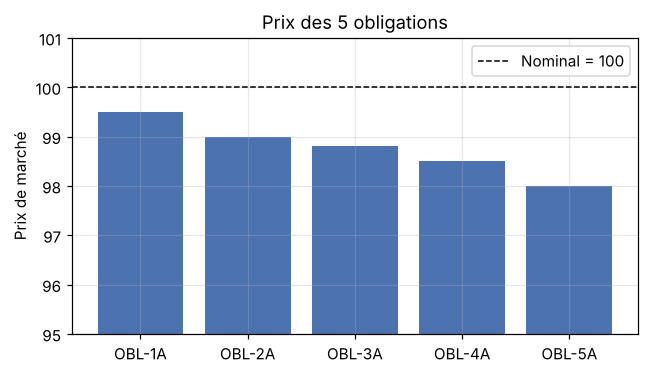

In [5]:
fig, ax = plt.subplots(figsize=(6,3.5))
ax.bar(df.nom, df.prix_marche, color='#4C72B0'); ax.axhline(100, color='k', ls='--', lw=1, label='Nominal = 100')
ax.set_ylim(95, 101); ax.set_ylabel('Prix de marché'); ax.set_title('Prix des 5 obligations'); ax.legend()
plt.tight_layout(); plt.savefig(FIG/'prix_obligations.png'); plt.show()